# ChestScan AI - Classification de radiographies thoraciques

**Sujet** : developpement d'un CNN (TensorFlow/Keras) qui classe une radiographie thoracique en **NORMAL** ou **PNEUMONIA**, puis deploiement d'un prototype **Streamlit**.

> **Prototype pedagogique. Ce modele n'est pas destine au diagnostic medical.**

## Deroulement du notebook
1. **Donnees** : chargement du dataset, comptage des images, images corrompues, analyse du desequilibre
2. **Pretraitement** : 180x180 RGB, normalisation [0,1], split train / validation / test sans fuite
3. **Modele** : CNN simple (Conv2D, MaxPooling2D, Flatten, Dense, Dropout)
4. **Entrainement** : augmentation (train seul), EarlyStopping, ReduceLROnPlateau, duree mesuree
5. **Evaluation** : metriques sur le test independant, matrice de confusion, faux positifs / faux negatifs
6. **Sauvegarde** : `.keras` + `config.json`, rechargement, fonction `predict_xray`
7. **Application** : `app.py` (Streamlit)

Dataset : [Kaggle - Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)

## 0. Imports et reproductibilite

On fixe la **seed** (graine aleatoire) partout. Sans seed, chaque execution donne des resultats legèrement differents et on ne peut pas comparer deux versions du modele.

In [1]:
# Bibliotheques : TensorFlow pour le CNN, scikit-learn pour les metriques, PIL pour les images
import json
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img

# Seed fixee partout : sans elle les resultats changent a chaque execution
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="darkgrid")
print("TensorFlow", tf.__version__)
# En Colab : Runtime > Change runtime type > GPU. Ici on affiche ce qui est utilise.
print("GPU detecte :", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0
GPU detecte : []


## 1. Donnees

**Source** : Kaggle, `paultimothymooney/chest-xray-pneumonia` (5863 radiographies JPEG, 2 classes).

Les images viennent de patients pediatriques (1 a 5 ans) d'un hopital de Guangzhou (Chine). Elles ont ete validees par des medecins. C'est un point important a connaitre : les resultats ne se generalisent pas automatiquement a d'autres populations (voir la section limites).

Le dossier contient deja un decoupage `train` / `val` / `test`, mais **le dossier `val` ne contient que 16 images** : il est trop petit pour servir de vraie validation. On le traite plus bas.

In [2]:
# Un meme code doit tourner en local ET sur Colab :
# - en local : dossier data/chest_xray (telecharge une fois, voir README.md)
# - sur Kaggle : /kaggle/input/...
# - sur Colab : telechargement via kagglehub (token Kaggle requis)
if os.path.exists(os.path.join("data", "chest_xray")):
    DATASET_PATH = os.path.join("data", "chest_xray")
elif os.path.exists("/kaggle/input/chest-xray-pneumonia/chest_xray"):
    DATASET_PATH = "/kaggle/input/chest-xray-pneumonia/chest_xray"
else:
    import kagglehub

    print("Telechargement du dataset via kagglehub (peut prendre plusieurs minutes)...")
    DATASET_PATH = os.path.join(
        kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"), "chest_xray"
    )

print("Dataset utilise :", DATASET_PATH)
# On affiche la structure pour verifier qu on est au bon endroit
print("Contenu :", sorted(os.listdir(DATASET_PATH)))

Dataset utilise : data\chest_xray
Contenu : ['.DS_Store', 'test', 'train', 'val']


In [3]:
# On compte les images par dossier et par classe AVANT tout traitement.
# C est la premiere question du jury : "combien d images par classe ?"
SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
# Le dataset contient aussi des fichiers macOS (.DS_Store) : ce ne sont pas des radiographies.
# On ne garde que les fichiers image, sinon les comptages sont faux.
EXTENSIONS_IMAGE = (".jpeg", ".jpg", ".png", ".bmp")

comptage = []
for dossier in SPLITS:
    for classe in CLASSES:
        chemin = os.path.join(DATASET_PATH, dossier, classe)
        fichiers = [f for f in os.listdir(chemin) if f.lower().endswith(EXTENSIONS_IMAGE)]
        comptage.append({"dossier": dossier, "classe": classe, "images": len(fichiers)})

df_comptage = pd.DataFrame(comptage)
tableau = df_comptage.pivot(index="dossier", columns="classe", values="images")
tableau["TOTAL"] = tableau.sum(axis=1)
print(tableau)
print("Total images dataset :", int(df_comptage["images"].sum()))

classe   NORMAL  PNEUMONIA  TOTAL
dossier                          
test        234        390    624
train      1341       3875   5216
val           8          8     16
Total images dataset : 5856


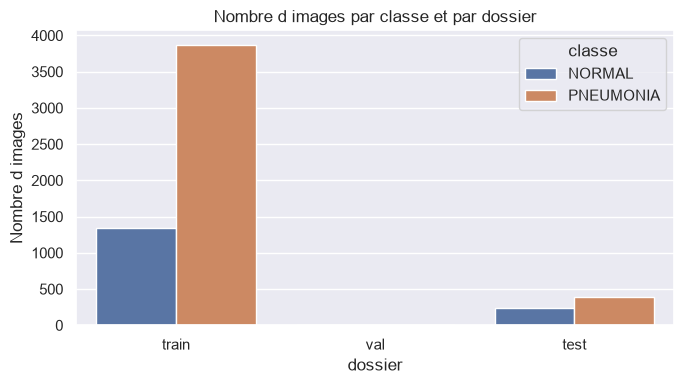

Train : 1341 NORMAL vs 3875 PNEUMONIA
Ratio PNEUMONIA / NORMAL = 2.89


In [4]:
# Graphique de distribution des classes : on voit tout de suite le desequilibre
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df_comptage, x="dossier", y="images", hue="classe", ax=ax)
ax.set_title("Nombre d images par classe et par dossier")
ax.set_ylabel("Nombre d images")
plt.tight_layout()
plt.show()

# Le ratio se calcule sur le train uniquement, c est la que le modele apprend
n_normal = int(tableau.loc["train", "NORMAL"])
n_pneumo = int(tableau.loc["train", "PNEUMONIA"])
print(f"Train : {n_normal} NORMAL vs {n_pneumo} PNEUMONIA")
print(f"Ratio PNEUMONIA / NORMAL = {n_pneumo / n_normal:.2f}")

### Analyse du desequilibre et strategie adaptee

Le train contient environ **2 fois plus de PNEUMONIA que de NORMAL**. Si on ne fait rien :
- le modele peut avoir une accuracy "elevee" en prevoyant surtout PNEUMONIA (strategie de paresse) ;
- l accuracy devient un mauvais indicateur : on prefere regarder **recall** et **precision**.

**Strategie choisie (3 mesures complémentaires) :**
1. **`class_weight`** : les images NORMAL recoivent un poids plus gros dans la loss, le modele doit donc les apprendre serieusement.
2. **Augmentation d images sur le train uniquement** : on varie les images pour eviter la memorisation.
3. **Metriques de classe** : precision / recall / F1 / AUC au lieu de l accuracy seule.

On ne fait **pas** de sous-echantillonnage (supprimer des PNEUMONIA) : on perdrait des donnees precieuses pour rien.

### Images corrompues

Le dataset contient quelques fichiers invalides (tronques ou non JPEG). Une image cassee en plein `fit()` ferait echouer tout l entrainement : on les detecte et on les exclut **maintenant**, en les comptant.

In [5]:
# Verification de chaque fichier avec PIL.
# verify() detecte les fichiers tronques sans decoder toute l image (rapide).
def est_lisible(chemin):
    try:
        with Image.open(chemin) as img:
            img.verify()
        return True
    except Exception:
        return False


lignes = []
corrompues = []
for dossier in SPLITS:
    for classe in CLASSES:
        chemin_dossier = os.path.join(DATASET_PATH, dossier, classe)
        for fichier in sorted(os.listdir(chemin_dossier)):
            if not fichier.lower().endswith(EXTENSIONS_IMAGE):
                continue  # on ignore .DS_Store et autres fichiers non image
            chemin = os.path.join(chemin_dossier, fichier)
            if est_lisible(chemin):
                lignes.append({"dossier": dossier, "classe": classe, "chemin": chemin})
            else:
                corrompues.append(chemin)

df_images = pd.DataFrame(lignes)
print("Images valides :", len(df_images))
print("Images corrompues exclues :", len(corrompues))
for chemin in corrompues:
    print("  -", chemin)

Images valides : 5856
Images corrompues exclues : 0


### Separation des donnees : train / validation / test (sans fuite)

Regles :
- Le **test du dataset reste independant** : on n y touche jamais pendant l entrainement ni pour choisir un hyperparametre. Il ne sert qu une fois, a la fin.
- Le **dossier `val` du dataset (16 images) est inutilisable** en l etat : on le fusionne au train.
- On decoupe ensuite un **train / validation stratifie 80/20** : la stratification garde la meme proportion de classes dans chaque part.
- La **seed est fixee** : le meme split a chaque execution.
- Le split se fait **avant** toute normalisation / augmentation : aucune image du train ne peut "fuir" dans la validation.

In [6]:
# Test independant : dossier test du dataset, intact
df_test = df_images[df_images["dossier"] == "test"].reset_index(drop=True)

# Train + val du dataset fusionnes, puis decoupe stratifiee 80/20
df_pool = df_images[df_images["dossier"] != "test"].reset_index(drop=True)
df_train, df_val = train_test_split(
    df_pool,
    test_size=0.2,
    stratify=df_pool["classe"],  # meme proportion de classes dans chaque part
    random_state=SEED,           # split reproductible
)

print(f"Train      : {len(df_train)} images")
print(f"Validation : {len(df_val)} images")
print(f"Test       : {len(df_test)} images (independant, jamais vu pendant l entrainement)")

# On verifie la proportion de classes dans chaque part (doit etre ~33 % / ~67 %)
for nom, df_part in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    part = df_part["classe"].value_counts(normalize=True) * 100
    print(f"{nom:11s} => NORMAL {part.get('NORMAL', 0):5.1f} % | PNEUMONIA {part.get('PNEUMONIA', 0):5.1f} %")

Train      : 4185 images
Validation : 1047 images
Test       : 624 images (independant, jamais vu pendant l entrainement)
train       => NORMAL  25.8 % | PNEUMONIA  74.2 %
validation  => NORMAL  25.8 % | PNEUMONIA  74.2 %
test        => NORMAL  37.5 % | PNEUMONIA  62.5 %


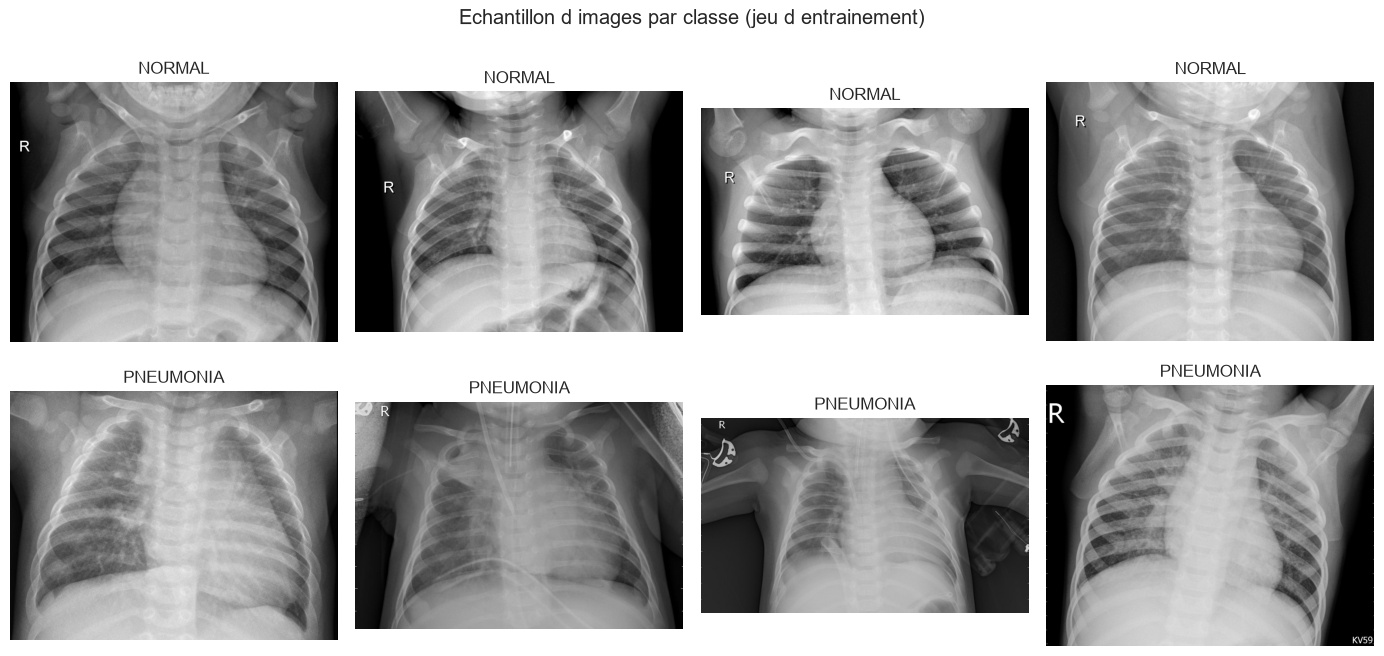

In [7]:
# Un echantillon par classe : on verifie visuellement que les labels des dossiers
# correspondent bien aux images (sinon tout le projet est invalide)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ligne, classe in enumerate(CLASSES):
    exemples = df_train[df_train["classe"] == classe].sample(4, random_state=SEED)
    for col, (_, rang) in enumerate(exemples.iterrows()):
        axes[ligne, col].imshow(Image.open(rang["chemin"]).convert("RGB"))
        axes[ligne, col].set_title(classe)
        axes[ligne, col].axis("off")
plt.suptitle("Echantillon d images par classe (jeu d entrainement)")
plt.tight_layout()
plt.show()

### Pretraitement

Choix imposes par le sujet et justifies :
- **180x180** : taille fixee par le cahier des charges (150x150 faisait gagner du temps mais n est pas conforme).
- **RGB (3 canaux)** : les radiographies sont en niveaux de gris, mais le modele est defini sur 3 canaux, comme une image classique. Ca rend le pretraitement identique a une image couleur.
- **Normalisation [0,1]** : on divise par 255 **une seule fois**, dans le générateur. Une double normalisation (ex. `/255` puis une couche `Rescaling`) fausserait les valeurs d entree.
- **Augmentation sur le train SEULEMENT** : l appliquer a la validation fausserait les metriques (on evaluerait des images transformees).

In [8]:
# Parametres du pretraitement : MEMES valeurs dans le notebook, predict_xray et app.py
IMG_SIZE = 180
BATCH_SIZE = 32
SEUIL = 0.5  # score PNEUMONIA >= 0.5 => classe PNEUMONIA

# Augmentation : uniquement sur le train
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,   # normalisation [0,1] appliquee UNE SEULE FOIS, ici
    rotation_range=20,   # rotations legeres
    zoom_range=0.15,     # zoom aleatoire
    width_shift_range=0.1,   # decalage horizontal
    height_shift_range=0.1,  # decalage vertical
    horizontal_flip=True,    # retournement horizontal (une radio peut etre vue dans les deux sens)
)

# Validation et test : SEULEMENT la normalisation, aucune transformation aleatoire
eval_datagen = ImageDataGenerator(rescale=1.0 / 255)


def creer_generateur(df, datagen, shuffle):
    # flow_from_dataframe : chemins + labels construits plus haut.
    # Les labels viennent des noms de dossiers (NORMAL / PNEUMONIA).
    return datagen.flow_from_dataframe(
        dataframe=df,
        x_col="chemin",
        y_col="classe",
        target_size=(IMG_SIZE, IMG_SIZE),  # redimension 180x180
        color_mode="rgb",                  # 3 canaux
        class_mode="binary",               # binaire => 1 neurone en sortie + sigmoide
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )


train_gen = creer_generateur(df_train, train_datagen, shuffle=True)
val_gen = creer_generateur(df_val, eval_datagen, shuffle=False)
test_gen = creer_generateur(df_test, eval_datagen, shuffle=False)

# L ordre des classes est donne par l alpha : NORMAL = 0, PNEUMONIA = 1
print("Classes detectees depuis les dossiers :", train_gen.class_indices)

Found 4185 validated image filenames belonging to 2 classes.
Found 1047 validated image filenames belonging to 2 classes.
Found 624 validated image filenames belonging to 2 classes.
Classes detectees depuis les dossiers : {'NORMAL': 0, 'PNEUMONIA': 1}


In [9]:
# Correction du desequilibre : on donne plus de poids aux images rares (NORMAL).
# compute_class_weight("balanced") => poids = n_total / (n_classes * n_par_classe)
y_train = train_gen.classes
valeurs = np.unique(y_train)
poids = compute_class_weight("balanced", classes=valeurs, y=y_train)
CLASS_WEIGHT = dict(zip(valeurs.tolist(), poids.tolist()))
print("Poids des classes (0 = NORMAL, 1 = PNEUMONIA) :", CLASS_WEIGHT)

Poids des classes (0 = NORMAL, 1 = PNEUMONIA) : {0: 1.9392956441149212, 1: 0.6736960721184804}


## 2. Modele

Architecture volontairement **simple et explicable** : chaque couche a un role clair.

| Couche | Role |
|--------|------|
| `Conv2D` | detecte des formes (bords, taches blanches = zones inflammees) |
| `MaxPooling2D` | reduit la taille en gardant l information utile (et ca accere l entrainement) |
| `Flatten` | aplatis le tableau 2D en vecteur |
| `Dense(512, relu)` | couche de decision |
| `Dropout(0.5)` | "eteint" 50 % des neurones au hasard : evite la memorisation (overfitting) |
| `Dense(1, sigmoide)` | **sortie binaire** : une probabilite entre 0 et 1 (0 = NORMAL, 1 = PNEUMONIA) |

**Compile** : `adam` (optimiseur standard, pas d apprentissage a regler), `binary_crossentropy` (la loss des 2 classes opposees), et 4 metriques car **en medical l accuracy ne suffit pas** : recall (quelques malades rates ?) et precision (faux alarmes ?).

In [10]:
# Reseau de neurones convolutif (CNN) : Conv2D + MaxPooling2D + Flatten + Dense + Dropout
model = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(512, activation="relu"),
        Dropout(0.5),  # anti-overfitting
        # Sortie binaire : 1 seul neurone + sigmoide => probabilite PNEUMONIA
        Dense(1, activation="sigmoid"),
    ]
)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",  # la bonne loss pour 2 classes
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)
model.summary()

C:\Users\Youcode\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     7,930,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,171,713 (31.17 MB)

 Trainable params: 8,171,713 (31.17 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrainement

Callbacks :
- **EarlyStopping** : on arrete quand la `val_loss` stagne (patience 5) et on **restaure les meilleurs poids**. Sans ca, on memorise le train (overfitting).
- **ReduceLROnPlateau** : si la `val_loss` stagne, on divise le pas d apprentissage par 2 : le modele peut encore progresser doucement.

La **duree est mesuree** : c est un critere du sujet (et utile pour justifier le choix du batch size).

In [11]:
# EarlyStopping : arrete l entrainement si la validation ne progresse plus
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
# ReduceLROnPlateau : baisse le learning rate si la validation stagne
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

EPOCHS = 20  # maximum : EarlyStopping arretera avant si la validation stagne

debut = time.time()
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=[early_stop, reduce_lr],
    class_weight=CLASS_WEIGHT,  # desequilibre corrige ici
)
duree_minutes = (time.time() - debut) / 60
print(f"Duree d entrainement : {duree_minutes:.1f} minutes")

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 245s 2s/step - accuracy: 0.7892 - auc: 0.8806 - loss: 0.4421 - precision: 0.9290 - recall: 0.7753 - val_accuracy: 0.8606 - val_auc: 0.9704 - val_loss: 0.3139 - val_precision: 0.9922 - val_recall: 0.8185 - learning_rate: 0.0010
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.8542 - auc: 0.9336 - loss: 0.3305 - precision: 0.9571 - recall: 0.8413 - val_accuracy: 0.7163 - val_auc: 0.9802 - val_loss: 0.5901 - val_precision: 1.0000 - val_recall: 0.6178 - learning_rate: 0.0010
Epoch 3/20
129/131 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.8826 - auc: 0.9505 - loss: 0.2787 - precision: 0.9701 - recall: 0.8686

KeyboardInterrupt: 

In [ ]:
# Courbes d entrainement : c est ici qu on detecte le surapprentissage.
# Surapprentissage (overfitting) : train baisse, validation remonte => le modele memorise.
# Sous-apprentissage : les deux restent hautes => le modele n a pas appris assez.
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
gamme = range(1, len(acc) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(gamme, acc, "o-", label="Train")
ax[0].plot(gamme, val_acc, "o-", label="Validation")
ax[0].set_title("Accuracy (train vs validation)")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(gamme, loss, "o-", label="Train")
ax[1].plot(gamme, val_loss, "o-", label="Validation")
ax[1].set_title("Loss (train vs validation)")
ax[1].set_xlabel("Epoch")
ax[1].legend()
plt.tight_layout()
plt.show()

print("Meilleure val_accuracy :", round(max(val_acc), 4))
print("Meilleure val_loss     :", round(min(val_loss), 4))
print("Nombre d epochs executes :", len(acc), "/", EPOCHS)

## 4. Evaluation sur le test independant

Rappel important : **le test n a servi a rien jusqu ici**. Ni l epoch, ni le seuil, ni l architecture n ont ete choisis avec le test. Il ne sert qu ici, une fois, pour juger le modele final.

Lecture des metriques :
- **accuracy** : proportion globale de bonnes predictions (trompeuse avec le desequilibre) ;
- **precision** (classe PNEUMONIA) : parmi les predits malades, combien le sont vraiment ;
- **recall** (classe PNEUMONIA) : parmi les vrais malades, combien ont ete detectes ;
- **F1** : moyenne harmonique precision/recall ;
- **ROC-AUC** : capacite a separer les deux classes quel que soit le seuil.

In [ ]:
# Prediction sur le test : proba PNEUMONIA puis decision au seuil
y_pred_proba = model.predict(test_gen, verbose=1).ravel()  # probabilite d etre PNEUMONIA
y_true = test_gen.classes                                   # labels reels (0 = NORMAL, 1 = PNEUMONIA)
y_pred = (y_pred_proba >= SEUIL).astype(int)                # decision au seuil 0.5

accuracy_test = float((y_pred == y_true).mean())
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_pred_proba)

print(f"Accuracy  : {accuracy_test:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

In [ ]:
# Matrice de confusion : les erreurs, concretement.
# Faux negatif (PNEUMONIA predit NORMAL) : le plus grave en medical, le malade repart sans traitement.
# Faux positif (NORMAL predit PNEUMONIA) : examen complementaire inutile, stress, cout.
matrice = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    matrice,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    ax=ax,
)
ax.set_xlabel("Classe predite")
ax.set_ylabel("Vraie classe")
ax.set_title("Matrice de confusion (test independant)")
plt.show()

vrais_negatifs = int(matrice[0, 0])  # NORMAL predit NORMAL
faux_positifs = int(matrice[0, 1])   # NORMAL predit PNEUMONIA
faux_negatifs = int(matrice[1, 0])   # PNEUMONIA predit NORMAL
vrais_positifs = int(matrice[1, 1])  # PNEUMONIA predit PNEUMONIA

print("Vrais negatifs (sains bien identifies)      :", vrais_negatifs)
print("Faux positifs (sains pris pour malades)     :", faux_positifs)
print("Vrais positifs (malades bien identifies)    :", vrais_positifs)
print("Faux negatifs (malades rates)               :", faux_negatifs)

In [ ]:
# Courbe ROC et effet du seuil.
# Baisser le seuil (0.5 -> 0.3) augmente le recall : moins de malades rates,
# mais plus de faux positifs. C est un arbitrage MEDICAL, pas technique.
fpr, tpr, _ = roc_curve(y_true, y_pred_proba)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax[0].plot([0, 1], [0, 1], "k--", label="hasard (AUC = 0.5)")
ax[0].set_xlabel("Taux de faux positifs")
ax[0].set_ylabel("Taux de vrais positifs (recall)")
ax[0].set_title("Courbe ROC (test independant)")
ax[0].legend()

lignes = []
for seuil_test in [0.3, 0.4, 0.5, 0.6, 0.7]:
    prediction_seuil = (y_pred_proba >= seuil_test).astype(int)
    lignes.append(
        {
            "seuil": seuil_test,
            "precision": precision_score(y_true, prediction_seuil, zero_division=0),
            "recall": recall_score(y_true, prediction_seuil, zero_division=0),
            "f1": f1_score(y_true, prediction_seuil, zero_division=0),
        }
    )
df_seuils = pd.DataFrame(lignes).set_index("seuil")
print(df_seuils.round(3))

ax[1].plot(df_seuils.index, df_seuils["precision"], "o-", label="precision")
ax[1].plot(df_seuils.index, df_seuils["recall"], "o-", label="recall")
ax[1].plot(df_seuils.index, df_seuils["f1"], "o-", label="f1")
ax[1].set_xlabel("Seuil de decision")
ax[1].set_title("Precision / recall / f1 selon le seuil")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Exemples de predictions correctes et incorrectes.
# Voir les erreurs aide a comprendre le modele : une radio floue ? une tache discrete ?
chemins_test = df_test["chemin"].values
index_incorrects = np.where(y_pred != y_true)[0]
index_corrects = np.where(y_pred == y_true)[0]


def afficher_exemples(indexes, titre, n_max=6):
    n = min(n_max, len(indexes))
    if n == 0:
        print(f"{titre} : aucun exemple")
        return
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for i, idx in enumerate(indexes[:n]):
        img = load_img(chemins_test[idx], target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb")
        ligne, col = divmod(i, 3)
        axes[ligne, col].imshow(img)
        reel = CLASSES[int(y_true[idx])]
        dit = CLASSES[int(y_pred[idx])]
        axes[ligne, col].set_title(f"Vrai : {reel} | Predit : {dit}\nscore = {y_pred_proba[idx]:.2f}")
        axes[ligne, col].axis("off")
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()


afficher_exemples(index_corrects, "Predictions correctes")
# On montre d abord les faux negatifs (les plus critiques), puis les faux positifs
index_fn = [i for i in index_incorrects if y_true[i] == 1]
index_fp = [i for i in index_incorrects if y_true[i] == 0]
afficher_exemples(index_fn, "Faux negatifs (malade rate)")
afficher_exemples(index_fp, "Faux positifs (fausse alarme)")
print(f"Erreurs sur le test : {len(index_incorrects)} / {len(y_true)}")

In [ ]:
# Comparaison train / validation / test : les trois scores doivent etre proches.
# train >> test => surapprentissage. Les trois faibles => sous-apprentissage.
resultats_train = model.evaluate(train_gen, verbose=0)
resultats_val = model.evaluate(val_gen, verbose=0)
resultats_test = model.evaluate(test_gen, verbose=0)

df_comparaison = pd.DataFrame(
    {"train": resultats_train, "validation": resultats_val, "test": resultats_test},
    index=model.metrics_names,
)
print(df_comparaison.round(4))

### Analyse critique des resultats

A remplir apres l execution, en regardant les chiffres au-dessus. Les questions a se poser :
1. **Quel est l ecart train / test ?** S il est faible, le modele generalise. S il est grand, il memorise.
2. **Ou sont les erreurs ?** Avec le desequilibre, les erreurs sont surtout de type NORMAL pris pour PNEUMONIA (faux positifs).
3. **Quel type d erreur est grave ?** En depistage, un **faux negatif** (malade rate) est bien plus dangereux qu un faux positif : on prefere donc un **recall eleve**, quitte a accepter plus de faux positifs. C est pour cela que le seuil est un choix medical.
4. **Le score est-il une probabilite calibree ?** Un score de 0.9 ne veut pas dire "90 % de chance d etre malade en realite", seulement "le modele est confiant". Attention a ne pas sur-interpréter.

## 5. Sauvegarde et rechargement

Deux fichiers sont sauvegardes :
- `chestscan_model.keras` : le modele entraine (format natif Keras) ;
- `config.json` : tout ce que l application doit savoir **sans relire le notebook** (taille d image, ordre des classes, seuil, resultats).

C est ce qui rend le deploiement possible : l app ne reentraine jamais, elle recharge.

In [ ]:
# Sauvegarde du modele au format .keras
model.save("chestscan_model.keras")

# La config contient ce dont l application a besoin pour rejouer le meme pretraitement
config = {
    "image_size": [IMG_SIZE, IMG_SIZE],
    "classes": list(CLASSES),  # index 0 = NORMAL, index 1 = PNEUMONIA
    "threshold": SEUIL,
    "optimizer": "adam",
    "loss": "binary_crossentropy",
    "dataset": "Kaggle paultimothymooney/chest-xray-pneumonia",
    "resultats_test": {
        "accuracy": round(accuracy_test, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(f1, 4),
        "roc_auc": round(roc_auc, 4),
    },
}
with open("config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print("Fichiers sauvegardes : chestscan_model.keras, config.json")
print(json.dumps(config["resultats_test"], indent=2))

In [ ]:
# Rechargement SANS reentrainement : on verifie que le modele recharge
# redonne exactement les memes predictions. C est le test de reproductibilite.
model_recharge = load_model("chestscan_model.keras")
y_proba_recharge = model_recharge.predict(test_gen, verbose=0).ravel()

identique = np.allclose(y_proba_recharge, y_pred_proba, atol=1e-6)
print("Predictions identiques apres rechargement :", bool(identique))
print("Plus grand ecart entre les deux scores :", float(np.max(np.abs(y_proba_recharge - y_pred_proba))))

### Fonction `predict_xray(image_path)`

Elle charge une image depuis le disque, applique **exactement le meme pretraitement** que l entrainement (RGB, 180x180, /255), predit, et retourne la classe + le score PNEUMONIA.

Point critique : si le pretraitement de `predict_xray` differe de celui du notebook (taille, canaux, normalisation oubliee), les predictions sont fausses **silencieusement**. C est la principale erreur de deploiement.

In [ ]:
# Fonction reutilisee telle quelle dans l application Streamlit
def predict_xray(image_path, modele=None, config_path="config.json"):
    # Charge, prepare et predit UNE image. Retourne (classe predite, score PNEUMONIA).
    with open(config_path, encoding="utf-8") as f:
        config_local = json.load(f)
    if modele is None:
        modele = load_model("chestscan_model.keras")

    # Meme pretraitement que ImageDataGenerator : RGB, 180x180, puis /255
    img = load_img(image_path, target_size=tuple(config_local["image_size"]), color_mode="rgb")
    x = img_to_array(img) / 255.0
    x = np.expand_dims(x, axis=0)  # le modele attend un lot, meme pour une seule image

    score = float(modele.predict(x, verbose=0)[0][0])
    seuil = config_local.get("threshold", 0.5)
    classe = config_local["classes"][1] if score >= seuil else config_local["classes"][0]
    return classe, score

In [ ]:
# Test de predict_xray sur plusieurs images du test independant (3 NORMAL + 3 PNEUMONIA)
exemples = pd.concat(
    [
        df_test[df_test["classe"] == "NORMAL"].sample(3, random_state=SEED),
        df_test[df_test["classe"] == "PNEUMONIA"].sample(3, random_state=SEED),
    ]
).to_dict("records")

lignes_test = []
for exemple in exemples:
    classe, score = predict_xray(exemple["chemin"])
    lignes_test.append(
        {
            "image": os.path.basename(exemple["chemin"]),
            "vraie_classe": exemple["classe"],
            "classe_predite": classe,
            "score_pneumonia": round(score, 3),
            "juste": classe == exemple["classe"],
        }
    )
df_test_predict = pd.DataFrame(lignes_test)
print(df_test_predict.to_string(index=False))
print(f"Bonnes predictions sur cet echantillon : {df_test_predict['juste'].sum()} / {len(df_test_predict)}")

In [ ]:
# Test d une entree invalide : la fonction doit echouer proprement
# (l application Streamlit gere le meme cas avec un message clair)
try:
    predict_xray("image_inexistante.jpg")
except Exception as erreur:
    print("Entree invalide geree :", type(erreur).__name__)

## 6. Limites et pistes d amelioration

### Limites (a connaitre pour l oral)
- **Population specifique** : enfants de 1 a 5 ans, un seul hopital (Guangzhou). Le modele n a pas ete teste sur des adultes ni sur d autres hopitaux : les resultats sur le test ne garantissent rien ailleurs (biais de population).
- **Test non externe** : test et train viennent du meme hopital et de la meme periode. Un vrai test medicale utiliserait des donnees externes.
- **Binaire trop simpliste** : "pneumonie" regroupe des causes tres differentes (bacterienne, virale). Le modele apprend une apparence, pas une cause.
- **Score mal calibre** : la probabilite sortie par la sigmoide n est pas une probabilite medicale.
- **Aucune explication** : le modele ne dit pas POURQUOI (pas de carte de chaleur).

### Pistes d amelioration (hors flux principal, non demande par le sujet)
1. **Transfer learning** (VGG16, EfficientNetB0 pre-entraines sur ImageNet) : gain de temps et de performance, mais le sujet demande un CNN entraine de zero, donc on reste sur le flux principal.
2. **Grad-CAM** : afficher les zones de l image qui ont fait pencher la decision.
3. **Seuil optimise metier** : choisir le seuil selon le cout des faux negatifs (courbe precision/recall ci-dessus).
4. **Test sur donnees externes** (NIH Chest X-ray, MIMIC-CXR) pour mesurer la degradation reelle.
5. **Autres architectures / regularisation** : batch normalization, plus de donnees, augmentation plus riche.

---

### A retenir
- **Sans fuite de donnees** : test independant, split avant normalisation, augmentation sur le train seul.
- **Un seul pretraitement** partout (notebook, `predict_xray`, `app.py`).
- **En medical, le recall compte** : un faux negatif laisse un malade sans traitement.